# CUT MATERIAL From Chapter 3

## CUT MATERIAL form Section 3.5

### Example sampling dist using pivotal transformation

Recall the sampling distribution of the difference between means `rvTDprice`.
Here are some examples of equivalent calculations using standard $t$-distribution.

In [108]:
dfD = calcdf(stdW, nW, stdE, nE)
rvT = tdist(df=dfD)

In [109]:
rvTDprice.ppf(0.95), rvTDprice.ppf(0.95)*seD + dhat

(4.060342411631915, 47.641013149955555)

In [110]:
rvTDprice.cdf(4), rvTDprice.cdf( (4-dhat)/seD )

(0.9406438830093703, 4.556607350244164e-08)

## NEW STUFF (TODO: merge with above)

TODO: distribute the following plots into appropriate subsections

#### Bootstrap approximation

In [111]:
from ministats import ci_dmeans
ci_dmeans(xsample,ysample, method="b")

[13.540768158298691, 34.5974768136927]

#### Analytical approximation

In [112]:
ci_dmeans(xsample,ysample, method="a")

[12.940807861945025, 35.44470301667319]

### Simulated sampling distribution under null

In [113]:
# CUT BECAUSE CONFUSING SINCE NEEDS A DIFFERENT, HYPOTHETICAL DATA MODEL
# # Two populations with the same mean X ~ N(100,13) and Y ~ N(100,17)
# from scipy.stats import norm
# muX0, muY0 = 100, 100
# sigmaX0, sigmaY0 = 13, 17
# rvX0 = norm(muX0, sigmaX0)
# rvY0 = norm(muY0, sigmaY0)

# # Two samples of sizes n=12 and m=15
# np.random.seed(55)
# n = 12
# x0sample = rvX0.rvs(n)

# np.random.seed(56)
# m = 15
# y0sample = rvY0.rvs(m)

In [114]:
# N = 10000
# dhats0 = []
# for j in range(0,N):
#     x0sample = rvX0.rvs(n)
#     y0sample = rvY0.rvs(m)
#     dhat0 = dmeans(x0sample, y0sample)
#     dhats0.append(dhat0)

# sns.histplot(dhats0, alpha=0.5);

#### Sampling distribution from the permutation test

0.0011998800119988001

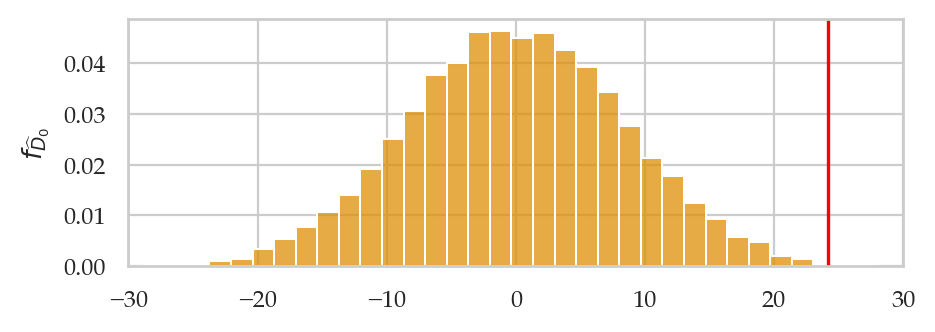

In [115]:
from scipy.stats import permutation_test

dhat = dmeans(xsample, ysample)

np.random.seed(42)
pres = permutation_test([xsample,ysample], statistic=dmeans, n_resamples=10000)
ax = sns.histplot(pres.null_distribution, stat="density", bins=35, color="C1")
plt.axvline(dhat, color="red")
ax.set_xlim(-30,30);
ax.set_ylabel("$f_{\\widehat{D}_0}$");
pres.pvalue

In [116]:
# np.random.seed(45)
from ministats import permutation_test_dmeans
permutation_test_dmeans(xsample, ysample)

0.0022

#### Sampling distribution from analytical approximation

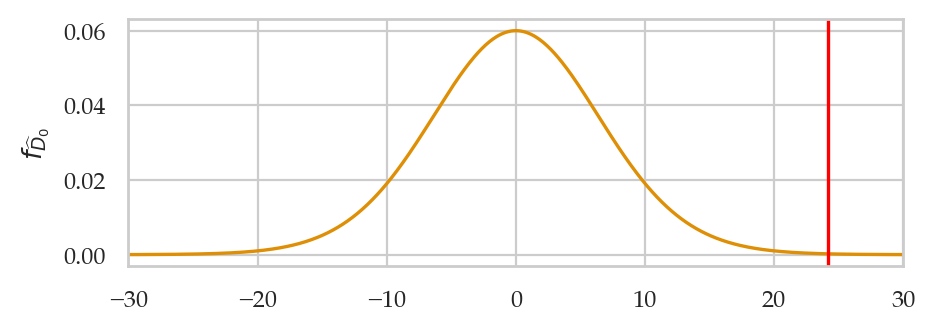

In [117]:
# Sample statistics
dhat = dmeans(xsample, ysample)
stdX, stdY = np.std(xsample,ddof=1), np.std(ysample,ddof=1)

# Estimated standard error
sehatD = np.sqrt(stdX**2/n + stdY**2/m)

# Degrees of freedom, the null model, and the t-statistic
dfD = calcdf(stdX, n, stdY, m)

# Calculate the p-value from the t-distribution
rvDhat = tdist(df=dfD, loc=0, scale=sehatD)
ax = plot_pdf(rvDhat, color="C1")
plt.axvline(dhat, color="red")
ax.set_xlim(-30, 30);
ax.set_xlabel("")
ax.set_ylabel("$f_{\\widehat{D}_0}$");

In [118]:
from ministats import ttest_dmeans
ttest_dmeans(xsample, ysample)

0.0011643603109388243